In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/clean_orders.csv",
                 parse_dates=["order_purchase_timestamp"])
print(df.shape)

C:\Users\abood\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


(96470, 16)


In [2]:
snapshot = df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm = df.groupby("customer_unique_id").agg(
    recency=("order_purchase_timestamp", lambda x: (snapshot - x.max()).days),
    frequency=("order_id", "nunique"),
    monetary=("price", "sum")
).reset_index()

print(rfm.shape)
rfm.describe()

(93350, 4)


,recency,frequency,monetary
count,93350.000000,93350.000000,93350.000000
mean,237.950070,1.033423,141.620235
std,152.589932,0.209106,215.702028
min,1.000000,1.000000,0.850000
25%,114.000000,1.000000,47.650000
50%,219.000000,1.000000,89.700000
75%,346.000000,1.000000,154.697500
max,714.000000,15.000000,13440.000000


In [3]:
rfm["frequency"].value_counts().head()

frequency
1    90549
2     2573
3      181
4       28
5        9
Name: count, dtype: int64

In [6]:
rfm.shape

(93350, 4)

In [7]:
rfm.describe()

,recency,frequency,monetary
count,93350.000000,93350.000000,93350.000000
mean,237.950070,1.033423,141.620235
std,152.589932,0.209106,215.702028
min,1.000000,1.000000,0.850000
25%,114.000000,1.000000,47.650000
50%,219.000000,1.000000,89.700000
75%,346.000000,1.000000,154.697500
max,714.000000,15.000000,13440.000000


In [8]:
rfm.value_counts()

customer_unique_id                recency  frequency  monetary
0000366f3b9a7992bf8c76cfdf3221e2  112      1          129.90      1
aa798bd609e98391c373f1f0f9102e3f  136      1          45.00       1
aa789d52aed60d7a80bfbbadd9e9ba13  107      1          44.90       1
aa7853ce070036b66ac47b1d98f3cf3d  393      1          122.61      1
aa7658e197aca5c7932cf21de7b48fd3  37       1          39.90       1
                                                                 ..
552a038a90f9896d8d9c4d86de8eeb93  524      1          21.00       1
5529aea7939027fa11e9386e52af84af  265      1          29.99       1
5528e8c8cdfa15940d89eb1d21866350  177      1          189.00      1
5528af7e794d044322ea7fc8cde9a086  283      1          118.90      1
ffffd2657e2aad2907e67c3e9daecbeb  484      1          56.99       1
Name: count, Length: 93350, dtype: int64

In [9]:
# Recency: أقل أيام = أحسن، فنعكس الترتيب (5 = الأحدث)
rfm["R"] = pd.qcut(rfm["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)

# Monetary: أكثر دفع = أحسن (rank لتجنب مشاكل التكرار)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Frequency: قاعدة بسيطة
rfm["F"] = rfm["frequency"].clip(upper=3)

rfm[["R", "F", "M"]].describe()

,R,F,M
count,93350.000000,93350.000000,93350.000000
mean,3.003182,1.032448,3.000000
std,1.414297,0.190473,1.414221
min,1.000000,1.000000,1.000000
25%,2.000000,1.000000,2.000000
50%,3.000000,1.000000,3.000000
75%,4.000000,1.000000,4.000000
max,5.000000,3.000000,5.000000


In [10]:
print(rfm["R"].value_counts().sort_index())
print(rfm["F"].value_counts().sort_index())
print(rfm["M"].value_counts().sort_index())

R
1    18638
2    18576
3    18709
4    18705
5    18722
Name: count, dtype: int64
F
1    90549
2     2573
3      228
Name: count, dtype: int64
M
1    18670
2    18670
3    18670
4    18670
5    18670
Name: count, dtype: int64


In [11]:
def segment(row):
    if row["F"] >= 2 and row["R"] >= 3:
        return "Loyal"
    if row["R"] >= 4 and row["M"] >= 4:
        return "Champions"
    if row["R"] >= 4:
        return "Recent"
    if row["R"] <= 2 and row["M"] >= 4:
        return "At Risk (High Value)"
    if row["M"] >= 4:
        return "Big Spenders"
    if row["R"] <= 2:
        return "Lost"
    return "Average"

rfm["segment"] = rfm.apply(segment, axis=1)

rfm["segment"].value_counts()


segment
Lost                    22752
Recent                  21701
Champions               14517
At Risk (High Value)    14462
Average                 11162
Big Spenders             6943
Loyal                    1813
Name: count, dtype: int64

In [12]:
summary = (rfm.groupby("segment")
              .agg(customers=("customer_unique_id", "count"),
                   avg_recency=("recency", "mean"),
                   avg_monetary=("monetary", "mean"),
                   total_revenue=("monetary", "sum"))
              .round(1))

summary["revenue_share_%"] = (summary["total_revenue"] / summary["total_revenue"].sum() * 100).round(1)
summary.sort_values("total_revenue", ascending=False)

,customers,avg_recency,avg_monetary,total_revenue,revenue_share_%
segment,,,,,
At Risk (High Value),14462,394.2,278.7,4030382.6,30.5
Champions,14517,91.9,267.1,3877101.2,29.3
Big Spenders,6943,220.6,249.4,1731443.6,13.1
Lost,22752,395.5,56.0,1273118.8,9.6
Recent,21701,89.8,55.5,1204911.2,9.1
Average,11162,220.4,55.4,618439.0,4.7
Loyal,1813,132.0,267.4,484852.5,3.7


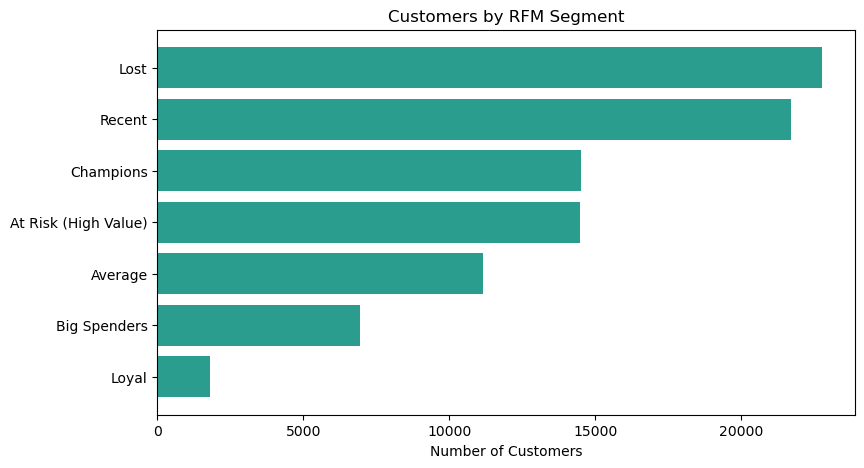

In [13]:
seg = summary.sort_values("customers", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(seg.index, seg["customers"], color="#2a9d8f")
plt.title("Customers by RFM Segment")
plt.xlabel("Number of Customers")
plt.savefig("../images/rfm_segments.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
rfm.to_csv("../data/rfm_segments.csv", index=False)
summary.to_csv("../data/rfm_summary.csv")


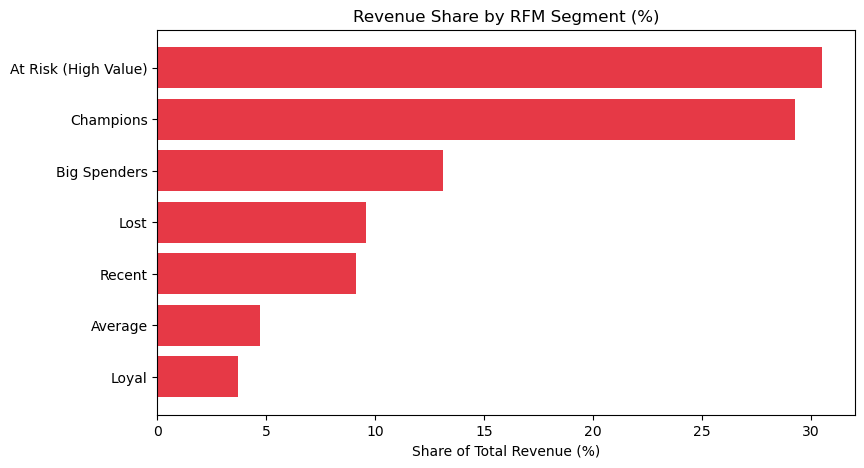

In [15]:
rev = summary.sort_values("revenue_share_%", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(rev.index, rev["revenue_share_%"], color="#e63946")
plt.title("Revenue Share by RFM Segment (%)")
plt.xlabel("Share of Total Revenue (%)")
plt.savefig("../images/rfm_revenue_share.png", dpi=150, bbox_inches="tight")
plt.show()